# EV Charging Site Selection — NY (DAC-Prioritized, Con Edison Territory)
### Q3 Milestone: Ranked Site Recommendations + Grid, Density, Sensitivity, Validation & Address Search

**Project:** 12-month CJF New York data project — site selection for EV charging in disadvantaged (DAC) and non-DAC communities, informed by Con Edison grid capacity.

**What's new in this version (all delivered this quarter):**
1. **Real grid capacity** — Con Edison feeder **EV Load Capacity (MW headroom)** from the hosting-capacity ArcGIS REST API, joined to tracts (proxy fallback if the endpoint isn't configured).
2. **True population density** — computed from each tract's polygon area (equivalent to TIGER/Line land area), replacing raw population for the accessibility criterion.
3. **Sensitivity analysis** — re-scores under equity-max / demand-max / grid-constrained weight scenarios and shows how the top sites shift.
4. **Validation** — cross-checks recommendations against **Charge Ready NY** installed projects (`data.ny.gov 9wxk-hakb`), existing chargers, and DAC coverage.
5. **Address search on the map** — type any address into the saved map (or call `locate_address()`), see its location, its tract's suitability, and its distance to the nearest recommended site.

An **Airflow DAG** (`dags/ev_site_selection_dag.py`) and a shared **`ev_pipeline.py`** module ship alongside this notebook for the Q1 ETL-orchestration sprint.

> Every source is fetched live and cached to `data/cache/`; if a source is unreachable the notebook falls back to a clearly-labelled synthetic NY sample so the demo never breaks. Real vs synthetic is printed at every step.


## 1. Data catalog

| # | Source | Provider | Endpoint / ID | Role |
|---|---|---|---|---|
| 1 | Final Disadvantaged Communities (DAC) 2023 | NYSERDA / CJWG | `data.ny.gov` `2e6c-s6fp` | Equity, traffic, burden, population, geometry |
| 2 | Electric Vehicle Registrations | NYS DMV | `data.ny.gov` `3vp6-cxmr` | EV adoption / demand (county) |
| 3 | Alternative Fuel Stations (public EVSE) | US DOE NREL AFDC | `developer.nrel.gov` | Existing infrastructure (gap) |
| 4 | **Con Edison Hosting Capacity — EV Load Capacity** | Con Edison | ArcGIS REST (configurable) | **Grid headroom (MW)** |
| 5 | **Charge Ready NY installed projects** | NYSERDA | `data.ny.gov` `9wxk-hakb` | **Validation** |
| 6 | Census / OSM geocoder | US Census / OSM | public | Address search |


## 2. Setup & configuration

Everything tunable lives in `CONFIG`. MCDA weights are asserted to sum to 1.0.

In [ ]:
import os, json, time, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)

CONFIG = {
    # --- geography -------------------------------------------------------
    "state_fips": "36",
    "target_counties": ["Bronx", "Kings", "New York", "Queens", "Richmond", "Westchester"],
    "restrict_to_target_counties": True,

    # --- API keys --------------------------------------------------------
    # Get a free key at https://developer.nrel.gov/signup and set NREL_API_KEY.
    # Falls back to the public DEMO_KEY (low rate limit) if unset — never commit a real key here.
    "nrel_api_key": os.environ.get("NREL_API_KEY", "DEMO_KEY"),

    # --- Con Edison hosting capacity (grid) ------------------------------
    # Paste the ArcGIS FeatureServer/MapServer LAYER url from the Hosting Capacity
    # map's "REST API" tab (coned.com/en/business-partners/hosting-capacity ->
    # open map -> REST API tab -> copy a layer endpoint ending in /FeatureServer/<n>
    # or /MapServer/<n>). Leave "" to use the documented proxy instead.
    "coned_hosting_capacity_url": "https://services.arcgis.com/ciPnsNFi1JLWVjva/ArcGIS/rest/services/CECONY_EVM_Feeders_Prod/FeatureServer/0",
    "coned_ev_capacity_field": "EV_HEADROOM",    # CECONY layer 0: EV_HEADROOM = Summer Load Capacity (MW); ELEC_HEADROOM = Winter
    "grid_join_radius_km": 1.5,                 # feeder-to-tract assignment radius

    # --- validation ------------------------------------------------------
    "charge_ready_dataset": "9wxk-hakb",        # Charge Ready NY installed projects

    # --- external toggles ------------------------------------------------
    "force_offline": False,
    "socrata_page_size": 50000,

    # --- model -----------------------------------------------------------
    "station_radius_km": 2.0,
    "coverage_radius_km": 2.0,                  # "served" threshold for validation + address search
    "top_n": 25,
    "min_population": 200,

    # --- MCDA weights (MUST sum to 1.0) ---------------------------------
    "weights": {
        "equity_dac":    0.25,
        "ev_demand":     0.20,
        "traffic":       0.15,
        "grid_capacity": 0.15,
        "accessibility": 0.10,
        "infra_gap":     0.15,
    },

    # --- sensitivity scenarios (each must sum to 1.0) -------------------
    "scenarios": {
        "balanced":        {"equity_dac":.25,"ev_demand":.20,"traffic":.15,"grid_capacity":.15,"accessibility":.10,"infra_gap":.15},
        "equity_max":      {"equity_dac":.45,"ev_demand":.15,"traffic":.10,"grid_capacity":.10,"accessibility":.05,"infra_gap":.15},
        "demand_max":      {"equity_dac":.15,"ev_demand":.35,"traffic":.15,"grid_capacity":.10,"accessibility":.10,"infra_gap":.15},
        "grid_constrained":{"equity_dac":.20,"ev_demand":.15,"traffic":.10,"grid_capacity":.35,"accessibility":.05,"infra_gap":.15},
    },

    "cache_dir": "data/cache",
    "output_dir": "outputs",
}

assert abs(sum(CONFIG["weights"].values()) - 1.0) < 1e-9, "weights must sum to 1.0"
for name, w in CONFIG["scenarios"].items():
    assert abs(sum(w.values()) - 1.0) < 1e-9, f"scenario {name} must sum to 1.0"

Path(CONFIG["cache_dir"]).mkdir(parents=True, exist_ok=True)
Path(CONFIG["output_dir"]).mkdir(parents=True, exist_ok=True)

DAC_DATASET   = "2e6c-s6fp"
EVREG_DATASET = "3vp6-cxmr"
SOCRATA_HOST  = "https://data.ny.gov"
print("Config OK. NREL key loaded:", CONFIG["nrel_api_key"][:6] + "…")
print("Con Ed hosting-capacity URL set:", bool(CONFIG["coned_hosting_capacity_url"]))

### 2.1  Helpers — caching, HTTP, geometry (area, centroid, point-in-polygon), ArcGIS puller

Only `pandas numpy requests folium branca matplotlib` are required; `pyarrow` is optional (CSV fallback).

In [20]:
import requests

try:
    import pyarrow  # noqa
    HAVE_PARQUET = True
except Exception:
    try:
        import fastparquet  # noqa
        HAVE_PARQUET = True
    except Exception:
        HAVE_PARQUET = False
        print("[note] no parquet engine -> caching/exports use CSV")

def _cache_path(name, ext=None):
    ext = ext or ("parquet" if HAVE_PARQUET else "csv")
    return os.path.join(CONFIG["cache_dir"], f"{name}.{ext}")

def cached_df(name, build_fn, force=False):
    p = _cache_path(name)
    if (not force) and os.path.exists(p):
        df = pd.read_parquet(p) if p.endswith(".parquet") else pd.read_csv(p, dtype=str)
        print(f"[cache] loaded '{name}' ({len(df):,} rows)")
        return df
    df = build_fn()
    try:
        (df.to_parquet(p, index=False) if p.endswith(".parquet") else df.to_csv(p, index=False))
        print(f"[cache] saved '{name}' ({len(df):,} rows)")
    except Exception as e:
        print(f"[cache] save failed for '{name}': {e}")
    return df

def cached_json(name, build_fn, force=False):
    p = _cache_path(name, "json")
    if (not force) and os.path.exists(p):
        with open(p) as f: return json.load(f)
    obj = build_fn()
    try:
        with open(p, "w") as f: json.dump(obj, f)
    except Exception as e:
        print(f"[cache] json save failed '{name}': {e}")
    return obj

def http_get(url, params=None, timeout=60):
    r = requests.get(url, params=params, timeout=timeout,
                     headers={"User-Agent": "cjf-ev-siteselection/2.0"})
    r.raise_for_status()
    return r

def haversine_km(lat1, lon1, lat2, lon2):
    R=6371.0; p1,p2=math.radians(lat1),math.radians(lat2)
    dphi=math.radians(lat2-lat1); dl=math.radians(lon2-lon1)
    a=math.sin(dphi/2)**2+math.cos(p1)*math.cos(p2)*math.sin(dl/2)**2
    return 2*R*math.asin(math.sqrt(a))

def _iter_rings(coords, out):
    ''' collect each linear ring (list of [lon,lat]) from (multi)polygon coords '''
    if not coords: return
    if isinstance(coords[0][0], (int, float)):
        out.append(coords)                       # a ring
    else:
        for c in coords: _iter_rings(c, out)

def feature_centroid(feature):
    acc=[]
    def walk(c):
        if isinstance(c,(list,tuple)) and c and isinstance(c[0],(int,float)): acc.append((c[0],c[1]))
        elif isinstance(c,(list,tuple)):
            for x in c: walk(x)
    walk(feature.get("geometry",{}).get("coordinates",[]))
    if not acc: return (None,None)
    return (sum(a[1] for a in acc)/len(acc), sum(a[0] for a in acc)/len(acc))  # lat, lon

def feature_area_km2(feature):
    ''' planar shoelace area on a local equirectangular projection (km^2) '''
    geom=feature.get("geometry",{}); rings=[]
    _iter_rings(geom.get("coordinates",[]), rings)
    if not rings: return np.nan
    lat0=feature_centroid(feature)[0]
    if lat0 is None: return np.nan
    R=6371.0; k=math.cos(math.radians(lat0))
    total=0.0
    for ring in rings:
        s=0.0
        for i in range(len(ring)-1):
            x1=math.radians(ring[i][0])*R*k;   y1=math.radians(ring[i][1])*R
            x2=math.radians(ring[i+1][0])*R*k; y2=math.radians(ring[i+1][1])*R
            s+=x1*y2-x2*y1
        total+=s/2.0
    return abs(total)   # outer+holes approx; fine for density

def point_in_feature(lat, lon, feature):
    rings=[]; _iter_rings(feature.get("geometry",{}).get("coordinates",[]), rings)
    inside=False
    for ring in rings:
        j=len(ring)-1
        for i in range(len(ring)):
            xi,yi=ring[i][0],ring[i][1]; xj,yj=ring[j][0],ring[j][1]
            if ((yi>lat)!=(yj>lat)) and (lon < (xj-xi)*(lat-yi)/((yj-yi)+1e-15)+xi):
                inside=not inside
            j=i
    return inside

def query_arcgis_layer(layer_url, where="1=1", out_fields="*", page=1000, max_records=20000):
    ''' generic ArcGIS FeatureServer/MapServer layer -> list of GeoJSON features '''
    feats, offset = [], 0
    while len(feats) < max_records:
        params={"where":where,"outFields":out_fields,"f":"geojson",
                "resultRecordCount":page,"resultOffset":offset,"outSR":4326}
        js=http_get(layer_url.rstrip("/")+"/query", params).json()
        batch=js.get("features",[])
        feats.extend(batch)
        if not batch or len(batch)<page: break
        offset+=page
    return feats

OFFLINE=CONFIG["force_offline"]
print("Helpers ready. Offline:", OFFLINE)


Helpers ready. Offline: False


## 3. Ingestion (Extract)

### 3.1  DAC 2023 — equity, traffic, burden, geometry

In [21]:
SELECT_FIELDS = ["geoid","county","city_town","nyc_region","urban_rural","redc",
    "dac_designation","population_count","household_count","combined_score",
    "percentile_rank_combined","burden_score_percentile","vulnerability_score_percentile",
    "traffic_number_vehicles","traffic_truck_highways","particulate_matter_25",
    "power_generation_facilities"]

def _dac_where():
    if not CONFIG["restrict_to_target_counties"]: return None
    return "county in(%s)" % ",".join("'%s'"%c for c in CONFIG["target_counties"])

def fetch_dac_live():
    url=f"{SOCRATA_HOST}/resource/{DAC_DATASET}.json"; where=_dac_where(); rows=[]; off=0
    while True:
        p={"$select":",".join(SELECT_FIELDS),"$limit":CONFIG["socrata_page_size"],"$offset":off}
        if where: p["$where"]=where
        b=http_get(url,p).json(); rows+=b
        if len(b)<CONFIG["socrata_page_size"]: break
        off+=CONFIG["socrata_page_size"]
    df=pd.DataFrame(rows); df["_source"]="live"; return df

def fetch_dac_geojson_live():
    url=f"{SOCRATA_HOST}/resource/{DAC_DATASET}.geojson"; where=_dac_where()
    p={"$select":"the_geom,geoid,dac_designation","$limit":60000}
    if where: p["$where"]=where
    return http_get(url,p).json()

def _synth_dac(n=120, seed=42):
    rng=np.random.default_rng(seed)
    centers={"Bronx":(40.85,-73.87),"Kings":(40.65,-73.95),"New York":(40.78,-73.97),
             "Queens":(40.70,-73.82),"Richmond":(40.58,-74.15),"Westchester":(41.12,-73.79)}
    fips={"Bronx":"005","Kings":"047","New York":"061","Queens":"081","Richmond":"085","Westchester":"119"}
    recs,feats=[],[]
    for county,(clat,clon) in centers.items():
        for i in range(n):
            gid=f"36{fips[county]}{i:06d}"; lat=clat+rng.normal(0,0.06); lon=clon+rng.normal(0,0.06)
            dac=rng.random()<(0.6 if county in ("Bronx","Kings") else 0.35)
            pct=float(np.clip(rng.beta(3,2) if dac else rng.beta(2,3),0,1))
            recs.append(dict(geoid=gid,county=county,city_town="New York city",
                nyc_region=("NYC" if county!="Westchester" else "Rest of State"),
                urban_rural=rng.choice(["urban","suburban"],p=[.8,.2]),
                redc=("New York City" if county!="Westchester" else "Mid-Hudson"),
                dac_designation=("Designated as DAC" if dac else "Not Designated as DAC"),
                population_count=int(np.clip(rng.normal(3800,1200),0,12000)),
                household_count=int(np.clip(rng.normal(1500,500),0,6000)),
                combined_score=float(30+pct*110),percentile_rank_combined=pct,
                burden_score_percentile=float(np.clip(rng.random(),0,1)),
                vulnerability_score_percentile=pct,
                traffic_number_vehicles=float(np.clip(rng.beta(2,2),0,1)),
                traffic_truck_highways=float(np.clip(rng.beta(2,3),0,1)),
                particulate_matter_25=float(np.clip(rng.random(),0,1)),
                power_generation_facilities=float(np.clip(rng.beta(1,6),0,1)),_source="synthetic"))
            d=0.012+rng.random()*0.02
            feats.append(dict(type="Feature",
                properties=dict(geoid=gid,dac_designation=recs[-1]["dac_designation"]),
                geometry=dict(type="Polygon",coordinates=[[
                    [lon-d,lat-d],[lon+d,lat-d],[lon+d,lat+d],[lon-d,lat+d],[lon-d,lat-d]]])))
    return pd.DataFrame(recs), dict(type="FeatureCollection",features=feats)

def load_dac():
    if OFFLINE: raise RuntimeError("offline")
    return fetch_dac_live()

try:
    dac_df=cached_df("dac_2023",load_dac)
    dac_geojson=cached_json("dac_2023_geojson",fetch_dac_geojson_live)
    SYNTH_DAC=False
except Exception as e:
    print(f"[fallback] DAC live unavailable ({type(e).__name__}) -> synthetic")
    dac_df,dac_geojson=_synth_dac(); SYNTH_DAC=True

print(f"\n>>> DAC: {'SYNTHETIC' if SYNTH_DAC else 'LIVE'} | rows={len(dac_df):,}")
dac_df.head(3)


[cache] loaded 'dac_2023' (2,390 rows)

>>> DAC: LIVE | rows=2,390


,geoid,county,city_town,nyc_region,urban_rural,redc,dac_designation,population_count,household_count,combined_score,percentile_rank_combined,burden_score_percentile,vulnerability_score_percentile,traffic_number_vehicles,traffic_truck_highways,particulate_matter_25,power_generation_facilities,_source
0,36005022901,Bronx,New York city,NYC,urban,New York City,Designated as DAC,5743,2011,112.165125674465,0.957941,0.741729,0.959406,0.989939216097254,0.995097037793667,0.705833848690991,0,live
1,36005025400,Bronx,New York city,NYC,urban,New York City,Not Designated as DAC,1997,755,90.0869216032839,0.689893,0.385236,0.75769,0.479773632362188,0.298672114402451,0.634508348794063,0,live
2,36005023000,Bronx,New York city,NYC,urban,New York City,Designated as DAC,2802,991,106.717213789371,0.908349,0.695823,0.910651,0.81639069377489,0.524004085801839,0.650381364667079,0,live


### 3.2  EV Registrations — adoption / demand (county)

In [22]:
def _find_col(cols, cands):
    low={c.lower():c for c in cols}
    for c in cands:
        if c in low: return low[c]
    for c in cols:
        if any(k in c.lower() for k in cands): return c
    return None

def fetch_evreg_live():
    url=f"{SOCRATA_HOST}/resource/{EVREG_DATASET}.json"
    probe=http_get(url,{"$limit":1}).json()
    if not probe: raise RuntimeError("empty")
    ccol=_find_col(list(probe[0].keys()),["county"])
    if not ccol: raise RuntimeError("no county col")
    rows=http_get(url,{"$select":f"{ccol} as county, count(1) as ev_registrations",
                       "$group":ccol,"$limit":5000}).json()
    df=pd.DataFrame(rows)
    df["ev_registrations"]=pd.to_numeric(df["ev_registrations"],errors="coerce")
    df["county"]=df["county"].astype(str).str.title().str.strip(); df["_source"]="live"; return df

def _synth_evreg(counties,seed=7):
    rng=np.random.default_rng(seed)
    base={"Bronx":9000,"Kings":21000,"New York":15000,"Queens":24000,"Richmond":8000,"Westchester":26000}
    return pd.DataFrame([{"county":c,"ev_registrations":int(base.get(c,8000)*rng.uniform(.8,1.2)),
                          "_source":"synthetic"} for c in counties])

def load_evreg():
    if OFFLINE: raise RuntimeError("offline")
    return fetch_evreg_live()

try:
    evreg_df=cached_df("ev_registrations_by_county",load_evreg)
    SYNTH_EV="_source" in evreg_df and (evreg_df["_source"]=="synthetic").any()
except Exception as e:
    print(f"[fallback] EV reg unavailable ({type(e).__name__}) -> synthetic")
    evreg_df=_synth_evreg(sorted(dac_df['county'].unique())); SYNTH_EV=True

evreg_df=evreg_df[evreg_df["county"].isin(dac_df["county"].unique())].copy()
print(f"\n>>> EV registrations: {'SYNTHETIC' if SYNTH_EV else 'LIVE'}")
evreg_df.sort_values('ev_registrations',ascending=False)


[cache] loaded 'ev_registrations_by_county' (63 rows)

>>> EV registrations: LIVE


,county,ev_registrations,_source
60,Westchester,22551,live
41,Queens,20946,live
23,Kings,15203,live
30,New York,8557,live
43,Richmond,6571,live
2,Bronx,4698,live


### 3.3  Existing chargers (NREL AFDC) — infrastructure gap

In [23]:
def fetch_stations_live():
    url="https://developer.nrel.gov/api/alt-fuel-stations/v1.json"
    p={"api_key":CONFIG["nrel_api_key"],"fuel_type":"ELEC","state":"NY",
       "status":"E","access":"public","limit":"all"}
    data=http_get(url,p).json()
    rows=[{"station_name":s.get("station_name"),"lat":s.get("latitude"),"lon":s.get("longitude"),
           "city":s.get("city"),"level2":s.get("ev_level2_evse_num"),"dcfc":s.get("ev_dc_fast_num")}
          for s in data.get("fuel_stations",[])]
    df=pd.DataFrame(rows); df["_source"]="live"; return df

def _synth_stations(geojson,seed=11,frac=0.25):
    rng=np.random.default_rng(seed); feats=geojson["features"]
    pick=rng.choice(len(feats),size=max(10,int(len(feats)*frac)),replace=False); rows=[]
    for i in pick:
        lat,lon=feature_centroid(feats[i])
        if lat is None: continue
        rows.append({"station_name":f"Synthetic Station {i}","lat":lat+rng.normal(0,0.004),
                     "lon":lon+rng.normal(0,0.004),"city":"NYC",
                     "level2":int(rng.integers(0,8)),"dcfc":int(rng.integers(0,4)),"_source":"synthetic"})
    return pd.DataFrame(rows)

def load_stations():
    if OFFLINE: raise RuntimeError("offline")
    return fetch_stations_live()

try:
    stations_df=cached_df("nrel_ev_stations_ny",load_stations)
    SYNTH_ST="_source" in stations_df and (stations_df["_source"]=="synthetic").any()
except Exception as e:
    print(f"[fallback] NREL unavailable ({type(e).__name__}) -> synthetic")
    stations_df=_synth_stations(dac_geojson); SYNTH_ST=True

stations_df["lat"]=pd.to_numeric(stations_df["lat"],errors="coerce")
stations_df["lon"]=pd.to_numeric(stations_df["lon"],errors="coerce")
stations_df=stations_df.dropna(subset=["lat","lon"]).reset_index(drop=True)
print(f"\n>>> Stations: {'SYNTHETIC' if SYNTH_ST else 'LIVE'} | {len(stations_df):,}")
stations_df.head(3)


[fallback] NREL unavailable (ConnectionError) -> synthetic



>>> Stations: SYNTHETIC | 597


,station_name,lat,lon,city,level2,dcfc,_source
0,Synthetic Station 2310,41.016493,-73.658823,NYC,5,1,synthetic
1,Synthetic Station 203,40.832887,-73.859773,NYC,4,0,synthetic
2,Synthetic Station 2096,40.560640,-74.187553,NYC,0,0,synthetic


### 3.4  Con Edison grid capacity — feeder **EV Load Capacity (MW)**

Con Edison's Hosting Capacity map publishes an **EV Load Capacity** value per feeder/network (the difference between rated capacity at the feeder head and last year's peak). We pull it from the ArcGIS REST layer set in `CONFIG["coned_hosting_capacity_url"]` and assign the nearest feeder's headroom to each tract.

**To enable real data:** open the [hosting-capacity map](https://www.coned.com/en/business-partners/hosting-capacity) → **REST API** tab → copy a layer URL (ends in `/FeatureServer/<n>` or `/MapServer/<n>`) → paste it into `CONFIG["coned_hosting_capacity_url"]` and re-run. If left blank, a **documented proxy** (inverse population density) is used and clearly flagged.

In [24]:
EV_CAP_FIELD_CANDIDATES = ["ev_headroom","ev_load","evloadcapacity","ev_load_capacity","evcap",
    "ev_hosting","ev_capacity","evloadmw","ev_load_mw","maxev","load_capacity","headroom"]

def fetch_coned_grid_live():
    url=CONFIG["coned_hosting_capacity_url"]
    if not url: raise RuntimeError("no coned url configured")
    feats=query_arcgis_layer(url, where="1=1", out_fields="*")
    if not feats: raise RuntimeError("no features returned")
    props=feats[0].get("properties",{}) or {}
    field=CONFIG["coned_ev_capacity_field"]
    if field is None:
        field=_find_col(list(props.keys()), EV_CAP_FIELD_CANDIDATES)
    if field is None:
        field=_find_col(list(props.keys()), ["hosting","capacity","mw"])
    rows=[]
    for f in feats:
        lat,lon=feature_centroid(f)
        if lat is None: continue
        val=pd.to_numeric(pd.Series([f.get("properties",{}).get(field)]),errors="coerce").iloc[0] if field else np.nan
        rows.append({"lat":lat,"lon":lon,"ev_mw":val})
    df=pd.DataFrame(rows); df["_source"]="live"
    print(f"[grid] detected EV-capacity field: {field}")
    return df

GRID_MODE="proxy"
try:
    if OFFLINE or not CONFIG["coned_hosting_capacity_url"]:
        raise RuntimeError("offline-or-unset")
    grid_df=cached_df("coned_grid_ev_capacity",fetch_coned_grid_live)
    grid_df["ev_mw"]=pd.to_numeric(grid_df["ev_mw"],errors="coerce")
    if grid_df["ev_mw"].notna().sum()==0: raise RuntimeError("no numeric EV capacity")
    GRID_MODE="live"
    print(f">>> Con Ed grid capacity: LIVE | {len(grid_df):,} feeders")
except Exception as e:
    grid_df=None
    print(f">>> Con Ed grid capacity: PROXY (reason: {type(e).__name__} — set CONFIG['coned_hosting_capacity_url'] for live)")


[cache] loaded 'coned_grid_ev_capacity' (20,000 rows)
>>> Con Ed grid capacity: LIVE | 20,000 feeders


### 3.5  Charge Ready NY installed projects — for validation (Section 11)

In [25]:
CR_DATASET=CONFIG["charge_ready_dataset"]

def fetch_charge_ready_live():
    url=f"{SOCRATA_HOST}/resource/{CR_DATASET}.json"
    probe=http_get(url,{"$limit":1}).json()
    if not probe: raise RuntimeError("empty")
    cols=list(probe[0].keys())
    latc=_find_col(cols,["latitude","lat"]); lonc=_find_col(cols,["longitude","lon","lng"])
    geoc=_find_col(cols,["georeference","location","point"]); cnty=_find_col(cols,["county"])
    rows=http_get(url,{"$limit":50000}).json(); df=pd.DataFrame(rows)
    def _xy(r):
        if latc and lonc and pd.notna(r.get(latc)) and pd.notna(r.get(lonc)):
            return pd.Series([pd.to_numeric(r.get(latc),errors="coerce"),
                              pd.to_numeric(r.get(lonc),errors="coerce")])
        g=r.get(geoc)
        if isinstance(g,dict) and g.get("coordinates"):
            return pd.Series([g["coordinates"][1],g["coordinates"][0]])
        return pd.Series([np.nan,np.nan])
    df[["lat","lon"]]=df.apply(_xy,axis=1)
    df["county"]=(df[cnty].astype(str).str.title().str.strip() if cnty else None)
    df["_source"]="live"
    return df[["county","lat","lon","_source"]]

def _synth_charge_ready(geojson,seed=23,n=45):
    rng=np.random.default_rng(seed); feats=geojson["features"]
    pick=rng.choice(len(feats),size=min(n,len(feats)),replace=False); rows=[]
    for i in pick:
        lat,lon=feature_centroid(feats[i])
        if lat is None: continue
        rows.append({"county":None,"lat":lat+rng.normal(0,0.005),"lon":lon+rng.normal(0,0.005),
                     "_source":"synthetic"})
    return pd.DataFrame(rows)

try:
    if OFFLINE: raise RuntimeError("offline")
    charge_ready_df=cached_df("charge_ready_ny",fetch_charge_ready_live)
    charge_ready_df["lat"]=pd.to_numeric(charge_ready_df["lat"],errors="coerce")
    charge_ready_df["lon"]=pd.to_numeric(charge_ready_df["lon"],errors="coerce")
    SYNTH_CR="_source" in charge_ready_df and (charge_ready_df["_source"]=="synthetic").any()
except Exception as e:
    print(f"[fallback] Charge Ready NY unavailable ({type(e).__name__}) -> synthetic")
    charge_ready_df=_synth_charge_ready(dac_geojson); SYNTH_CR=True

charge_ready_df=charge_ready_df.dropna(subset=["lat","lon"]).reset_index(drop=True)
print(f"\n>>> Charge Ready NY: {'SYNTHETIC' if SYNTH_CR else 'LIVE'} | {len(charge_ready_df):,} installed projects")
charge_ready_df.head(3)


[cache] loaded 'charge_ready_ny' (1,150 rows)

>>> Charge Ready NY: LIVE | 1,119 installed projects


,county,lat,lon,_source
0,Putnam,41.37544,-73.72685,live
1,Westchester,41.02890,-73.76169,live
2,Nassau,40.72996,-73.59246,live


## 4. Cleaning & preprocessing (Transform)

Handles the real-data gotchas: Socrata returns strings (coerce), percentiles clipped to [0,1], GEOID standardized to 11-char, near-empty tracts dropped. **New:** tract **area (km²)** and **population density** computed from geometry.

In [26]:
num_cols=["population_count","household_count","combined_score","percentile_rank_combined",
    "burden_score_percentile","vulnerability_score_percentile","traffic_number_vehicles",
    "traffic_truck_highways","particulate_matter_25","power_generation_facilities"]
dac=dac_df.copy()
for c in num_cols:
    if c in dac.columns: dac[c]=pd.to_numeric(dac[c],errors="coerce")
dac["geoid"]=dac["geoid"].astype(str).str.replace(r"\.0$","",regex=True).str.zfill(11)
dac["county_fips"]=dac["geoid"].str[2:5]
for c in ["percentile_rank_combined","burden_score_percentile","vulnerability_score_percentile",
          "traffic_number_vehicles","traffic_truck_highways","particulate_matter_25",
          "power_generation_facilities"]:
    if c in dac.columns: dac[c]=dac[c].clip(0,1)
dac["is_dac"]=dac["dac_designation"].str.strip().eq("Designated as DAC")

# --- geometry-derived area, centroid, density ---
area={}; cent={}
for f in dac_geojson.get("features",[]):
    g=str(f.get("properties",{}).get("geoid","")).zfill(11)
    area[g]=feature_area_km2(f); cent[g]=feature_centroid(f)
dac["area_km2"]=dac["geoid"].map(area)
dac["lat"]=dac["geoid"].map(lambda g:cent.get(g,(None,None))[0])
dac["lon"]=dac["geoid"].map(lambda g:cent.get(g,(None,None))[1])
dac["pop_density"]=dac["population_count"]/dac["area_km2"].replace(0,np.nan)

before=len(dac)
dac=dac[dac["population_count"].fillna(0)>=CONFIG["min_population"]].drop_duplicates("geoid").reset_index(drop=True)
for c in ["area_km2","pop_density","lat","lon"]:
    cm=dac.groupby("county")[c].transform("median"); dac[c]=dac[c].fillna(cm)
print(f"Cleaned: {before:,} -> {len(dac):,} tracts | DAC={dac['is_dac'].sum():,} non-DAC={(~dac['is_dac']).sum():,}")
print(f"Density (people/km²): median={dac['pop_density'].median():.0f}  max={dac['pop_density'].max():.0f}")

county_pop=dac.groupby("county",as_index=False)["population_count"].sum().rename(columns={"population_count":"county_population"})
ev=evreg_df.merge(county_pop,on="county",how="right")
ev["ev_registrations"]=ev["ev_registrations"].fillna(ev["ev_registrations"].median())
ev["ev_per_1k"]=1000*ev["ev_registrations"]/ev["county_population"].replace(0,np.nan)
ev[["county","ev_registrations","county_population","ev_per_1k"]].sort_values("ev_per_1k",ascending=False)


Cleaned: 2,390 -> 2,325 tracts | DAC=1,056 non-DAC=1,269
Density (people/km²): median=14951  max=96478


,county,ev_registrations,county_population,ev_per_1k
5,Westchester,22551,968890,23.275088
4,Richmond,6571,474870,13.837471
3,Queens,20946,2287207,9.157894
1,Kings,15203,2589929,5.870045
2,New York,8557,1631318,5.245452
0,Bronx,4698,1434874,3.274155


## 5. Integration — combined tract master table

Assign existing chargers and Con Ed feeder headroom to each tract; join EV adoption.

In [27]:
R=CONFIG["station_radius_km"]
st_lat=stations_df["lat"].to_numpy(); st_lon=stations_df["lon"].to_numpy()
def count_within(lat,lon,arr_lat,arr_lon,radius):
    if not len(arr_lat) or pd.isna(lat): return 0
    dlat=radius/111.0; dlon=radius/(111.0*max(math.cos(math.radians(lat)),1e-3))
    m=(np.abs(arr_lat-lat)<=dlat)&(np.abs(arr_lon-lon)<=dlon)
    if not m.any(): return 0
    return int(sum(haversine_km(lat,lon,a,b)<=radius for a,b in zip(arr_lat[m],arr_lon[m])))
dac["stations_within_r"]=[count_within(la,lo,st_lat,st_lon,R) for la,lo in zip(dac["lat"],dac["lon"])]

if GRID_MODE=="live" and grid_df is not None:
    g_lat=grid_df["lat"].to_numpy(); g_lon=grid_df["lon"].to_numpy(); g_mw=grid_df["ev_mw"].to_numpy()
    Rg=CONFIG["grid_join_radius_km"]
    def nearest_mw(lat,lon):
        if pd.isna(lat) or not len(g_lat): return np.nan
        dlat=Rg/111.0; dlon=Rg/(111.0*max(math.cos(math.radians(lat)),1e-3))
        m=(np.abs(g_lat-lat)<=dlat)&(np.abs(g_lon-lon)<=dlon)
        if not m.any():
            d=[haversine_km(lat,lon,a,b) for a,b in zip(g_lat,g_lon)]
            return float(g_mw[int(np.argmin(d))])
        cand=np.where(m)[0]; d=[haversine_km(lat,lon,g_lat[i],g_lon[i]) for i in cand]
        return float(g_mw[cand[int(np.argmin(d))]])
    dac["grid_headroom_mw"]=[nearest_mw(la,lo) for la,lo in zip(dac["lat"],dac["lon"])]
    print(f"Grid headroom joined (LIVE). Median MW={dac['grid_headroom_mw'].median():.2f}")
else:
    dac["grid_headroom_mw"]=np.nan

master=dac.merge(ev[["county","ev_registrations","ev_per_1k"]],on="county",how="left")
print(f"Master: {master.shape[0]:,} tracts x {master.shape[1]} cols | "
      f"tracts w/ >=1 charger ≤{R}km: {(master['stations_within_r']>0).mean():.0%}")
master[["geoid","county","is_dac","population_count","pop_density","percentile_rank_combined",
        "ev_per_1k","traffic_number_vehicles","stations_within_r","grid_headroom_mw"]].head()


Grid headroom joined (LIVE). Median MW=0.63
Master: 2,325 tracts x 28 cols | tracts w/ >=1 charger ≤2.0km: 96%


,geoid,county,is_dac,population_count,pop_density,percentile_rank_combined,ev_per_1k,traffic_number_vehicles,stations_within_r,grid_headroom_mw
0,36005022901,Bronx,True,5743,47173.795483,0.957941,3.274155,0.989939,22,4.45950
1,36005025400,Bronx,False,1997,11767.171490,0.689893,3.274155,0.479774,9,0.35544
2,36005023000,Bronx,True,2802,17602.257014,0.908349,3.274155,0.816391,14,0.73552
3,36005023302,Bronx,True,3706,59296.503644,0.937016,3.274155,0.945923,24,4.45950
4,36005023200,Bronx,True,2476,17372.160080,0.911279,3.274155,0.515615,15,0.73552


## 6. Feature engineering — the six MCDA criteria

| Criterion | Source | Direction |
|---|---|---|
| `equity_dac` | DAC combined-score percentile | ↑ higher need |
| `ev_demand` | EV registrations / 1k (county) | ↑ more demand |
| `traffic` | `traffic_number_vehicles` pct | ↑ throughput |
| `grid_capacity` | **Con Ed feeder EV headroom (MW)** — live, else proxy | ↑ more headroom |
| `accessibility` | **population density (people/km²)** | ↑ denser = better served |
| `infra_gap` | 1/(1+chargers within radius) | ↑ fewer nearby |

In [28]:
m=master.copy()
m["equity_dac"]=m["percentile_rank_combined"].fillna(m["percentile_rank_combined"].median())
m["ev_demand"]=m["ev_per_1k"].fillna(m["ev_per_1k"].median())
traf=m["traffic_number_vehicles"]
if traf.isna().all(): traf=m["traffic_truck_highways"]
m["traffic"]=traf.fillna(traf.median())

if GRID_MODE=="live" and m["grid_headroom_mw"].notna().any():
    m["grid_capacity"]=m["grid_headroom_mw"].fillna(m["grid_headroom_mw"].median())
    GRID_LABEL="Con Ed EV Load Capacity (MW, live)"
else:
    dens=(m["pop_density"]-m["pop_density"].min())/(m["pop_density"].max()-m["pop_density"].min()+1e-9)
    m["grid_capacity"]=1-dens
    GRID_LABEL="PROXY = 1 - normalized density (set Con Ed URL for live)"

m["accessibility"]=m["pop_density"].fillna(m["pop_density"].median())
m["infra_gap"]=1.0/(1.0+m["stations_within_r"])
criteria=list(CONFIG["weights"].keys())
print("grid_capacity source:", GRID_LABEL)
m[criteria].describe().round(3)


grid_capacity source: Con Ed EV Load Capacity (MW, live)


,equity_dac,ev_demand,traffic,grid_capacity,accessibility,infra_gap
count,2325.000,2325.000,2325.000,2325.000,2325.000,2325.000
mean,0.638,8.362,0.673,1.794,17833.298,0.153
std,0.245,5.444,0.225,2.430,13769.981,0.195
min,0.000,3.274,0.000,0.000,74.061,0.034
25%,0.470,5.245,0.519,0.000,7541.118,0.062
50%,0.669,5.870,0.702,0.633,14951.403,0.083
75%,0.843,9.158,0.863,2.815,24510.630,0.143
max,1.000,23.275,1.000,10.943,96478.188,1.000


## 7. Normalize, weight & score

In [29]:
def minmax(s):
    s=s.astype(float); lo,hi=s.min(),s.max()
    return pd.Series(0.5,index=s.index) if hi-lo<1e-12 else (s-lo)/(hi-lo)

def score_with(weights, frame):
    out=frame.copy()
    for c in criteria: out[c+"_n"]=minmax(out[c])
    out["suitability_score"]=sum(out[c+"_n"]*weights[c] for c in criteria)*100.0
    for c in criteria: out[c+"_contrib"]=out[c+"_n"]*weights[c]*100.0
    out["rank"]=out["suitability_score"].rank(ascending=False,method="first").astype(int)
    return out

m=score_with(CONFIG["weights"], m)
print(f"Scored {len(m):,} tracts | score {m['suitability_score'].min():.1f}–{m['suitability_score'].max():.1f} "
      f"(mean {m['suitability_score'].mean():.1f})")
m.sort_values("suitability_score",ascending=False)[
    ["rank","geoid","county","is_dac","suitability_score"]+[c+"_n" for c in criteria]].head(10).round(3)


Scored 2,325 tracts | score 7.8–74.8 (mean 37.3)


,rank,geoid,county,is_dac,suitability_score,equity_dac_n,ev_demand_n,traffic_n,grid_capacity_n,accessibility_n,infra_gap_n
2183,1,36119014100,Westchester,True,74.816,0.983,1.0,0.758,0.252,0.011,1.000
2211,2,36119013600,Westchester,True,70.750,0.764,1.0,0.565,0.541,0.006,1.000
2244,3,36119007800,Westchester,True,70.607,0.804,1.0,0.962,0.047,0.037,1.000
2263,4,36119001000,Westchester,True,69.308,0.982,1.0,0.851,0.257,0.090,0.482
2212,5,36119013301,Westchester,True,68.448,0.943,1.0,0.563,0.087,0.013,1.000
2240,6,36119007900,Westchester,True,67.776,0.780,1.0,0.780,0.054,0.076,1.000
2143,7,36119001101,Westchester,True,67.770,0.967,1.0,0.870,0.257,0.203,0.310
2190,8,36119000401,Westchester,True,66.580,0.978,1.0,0.743,0.221,0.045,0.482
2218,9,36119011500,Westchester,True,66.536,0.713,1.0,0.766,0.139,0.013,1.000
2189,10,36119000300,Westchester,True,66.006,0.974,1.0,0.803,0.257,0.111,0.310


## 8. Ranked site recommendations

In [30]:
N=CONFIG["top_n"]
cols_out=["rank","geoid","county","city_town","is_dac","suitability_score","population_count",
          "pop_density","ev_per_1k","stations_within_r","grid_headroom_mw","lat","lon"]+[c+"_n" for c in criteria]
cols_out=[c for c in cols_out if c in m.columns]
top_overall=m.sort_values("suitability_score",ascending=False).head(N)[cols_out].reset_index(drop=True)
top_dac=m[m["is_dac"]].sort_values("suitability_score",ascending=False).head(N)[cols_out].reset_index(drop=True)
print(f"TOP {N} OVERALL — DAC share {top_overall['is_dac'].mean():.0%}")
display(top_overall.round(3))
print(f"\nTOP {N} within DAC communities")
display(top_dac.round(3))


TOP 25 OVERALL — DAC share 96%


,rank,geoid,county,city_town,is_dac,suitability_score,population_count,pop_density,ev_per_1k,stations_within_r,grid_headroom_mw,lat,lon,equity_dac_n,ev_demand_n,traffic_n,grid_capacity_n,accessibility_n,infra_gap_n
0,1,36119014100,Westchester,Peekskill city,True,74.816,6373,1092.748,23.275,0,2.753,41.277,-73.933,0.983,1.000,0.758,0.252,0.011,1.000
1,2,36119013600,Westchester,Ossining village,True,70.750,4343,670.590,23.275,0,5.922,41.172,-73.867,0.764,1.000,0.565,0.541,0.006,1.000
2,3,36119007800,Westchester,Port Chester village,True,70.607,4616,3625.909,23.275,0,0.514,40.993,-73.667,0.804,1.000,0.962,0.047,0.037,1.000
3,4,36119001000,Westchester,Yonkers city,True,69.308,1786,8723.806,23.275,1,2.815,40.937,-73.886,0.982,1.000,0.851,0.257,0.090,0.482
4,5,36119013301,Westchester,Ossining village,True,68.448,3331,1305.758,23.275,0,0.950,41.160,-73.867,0.943,1.000,0.563,0.087,0.013,1.000
5,6,36119007900,Westchester,Port Chester village,True,67.776,7693,7433.630,23.275,0,0.591,40.999,-73.674,0.780,1.000,0.780,0.054,0.076,1.000
6,7,36119001101,Westchester,Yonkers city,True,67.770,3445,19623.261,23.275,2,2.815,40.934,-73.890,0.967,1.000,0.870,0.257,0.203,0.310
7,8,36119000401,Westchester,Yonkers city,True,66.580,4191,4416.828,23.275,1,2.421,40.937,-73.899,0.978,1.000,0.743,0.221,0.045,0.482
8,9,36119011500,Westchester,Tarrytown village,True,66.536,5678,1329.565,23.275,0,1.520,41.072,-73.868,0.713,1.000,0.766,0.139,0.013,1.000
9,10,36119000300,Westchester,Yonkers city,True,66.006,4223,10785.421,23.275,2,2.815,40.932,-73.897,0.974,1.000,0.803,0.257,0.111,0.310



TOP 25 within DAC communities


,rank,geoid,county,city_town,is_dac,suitability_score,population_count,pop_density,ev_per_1k,stations_within_r,grid_headroom_mw,lat,lon,equity_dac_n,ev_demand_n,traffic_n,grid_capacity_n,accessibility_n,infra_gap_n
0,1,36119014100,Westchester,Peekskill city,True,74.816,6373,1092.748,23.275,0,2.753,41.277,-73.933,0.983,1.000,0.758,0.252,0.011,1.000
1,2,36119013600,Westchester,Ossining village,True,70.750,4343,670.590,23.275,0,5.922,41.172,-73.867,0.764,1.000,0.565,0.541,0.006,1.000
2,3,36119007800,Westchester,Port Chester village,True,70.607,4616,3625.909,23.275,0,0.514,40.993,-73.667,0.804,1.000,0.962,0.047,0.037,1.000
3,4,36119001000,Westchester,Yonkers city,True,69.308,1786,8723.806,23.275,1,2.815,40.937,-73.886,0.982,1.000,0.851,0.257,0.090,0.482
4,5,36119013301,Westchester,Ossining village,True,68.448,3331,1305.758,23.275,0,0.950,41.160,-73.867,0.943,1.000,0.563,0.087,0.013,1.000
5,6,36119007900,Westchester,Port Chester village,True,67.776,7693,7433.630,23.275,0,0.591,40.999,-73.674,0.780,1.000,0.780,0.054,0.076,1.000
6,7,36119001101,Westchester,Yonkers city,True,67.770,3445,19623.261,23.275,2,2.815,40.934,-73.890,0.967,1.000,0.870,0.257,0.203,0.310
7,8,36119000401,Westchester,Yonkers city,True,66.580,4191,4416.828,23.275,1,2.421,40.937,-73.899,0.978,1.000,0.743,0.221,0.045,0.482
8,9,36119011500,Westchester,Tarrytown village,True,66.536,5678,1329.565,23.275,0,1.520,41.072,-73.868,0.713,1.000,0.766,0.139,0.013,1.000
9,10,36119000300,Westchester,Yonkers city,True,66.006,4223,10785.421,23.275,2,2.815,40.932,-73.897,0.974,1.000,0.803,0.257,0.111,0.310


## 9. Sensitivity analysis — how the ranking shifts with priorities

We re-score every tract under four weighting scenarios (**balanced**, **equity-max**, **demand-max**, **grid-constrained**) and measure how stable the top-N is. High overlap = a robust recommendation that survives reasonable disagreement about priorities; low overlap = the choice is genuinely priority-dependent (worth discussing with stakeholders).

In [31]:
scen_scores={}; scen_topsets={}
for name,w in CONFIG["scenarios"].items():
    s=score_with(w,m)
    scen_scores[name]=s.set_index("geoid")["rank"]
    scen_topsets[name]=set(s.sort_values("suitability_score",ascending=False).head(N)["geoid"])

names=list(CONFIG["scenarios"].keys())
J=pd.DataFrame(index=names,columns=names,dtype=float)
for a in names:
    for b in names:
        A,B=scen_topsets[a],scen_topsets[b]
        J.loc[a,b]=len(A&B)/len(A|B) if (A|B) else 1.0
print("Top-%d overlap (Jaccard) across scenarios:"%N); display(J.round(2))

robust=set.intersection(*scen_topsets.values())
print(f"\nRobust sites (in top-{N} under ALL scenarios): {len(robust)}")
rank_tbl=pd.DataFrame({name:scen_scores[name] for name in names})
rank_tbl["best"]=rank_tbl.min(axis=1); rank_tbl["worst"]=rank_tbl.max(axis=1)
rank_tbl["rank_spread"]=rank_tbl["worst"]-rank_tbl["best"]
robust_tbl=(rank_tbl.loc[sorted(robust)].join(m.set_index("geoid")[["county","is_dac"]])
            .sort_values("balanced")) if robust else pd.DataFrame()
display(robust_tbl.head(15))


Top-25 overlap (Jaccard) across scenarios:


,balanced,equity_max,demand_max,grid_constrained
balanced,1.00,0.72,0.61,0.28
equity_max,0.72,1.00,0.47,0.22
demand_max,0.61,0.47,1.00,0.25
grid_constrained,0.28,0.22,0.25,1.00



Robust sites (in top-25 under ALL scenarios): 8


,balanced,equity_max,demand_max,grid_constrained,best,worst,rank_spread,county,is_dac
geoid,,,,,,,,,
36119014100,1,1,1,2,1,2,1,Westchester,True
36119013600,2,7,3,1,1,7,6,Westchester,True
36119007800,3,4,2,19,2,19,17,Westchester,True
36119001000,4,3,8,11,3,11,8,Westchester,True
36119013301,5,2,6,18,2,18,16,Westchester,True
36119001101,7,6,9,17,6,17,11,Westchester,True
36119000401,8,5,11,22,5,22,17,Westchester,True
36119008000,15,18,15,20,15,20,5,Westchester,True


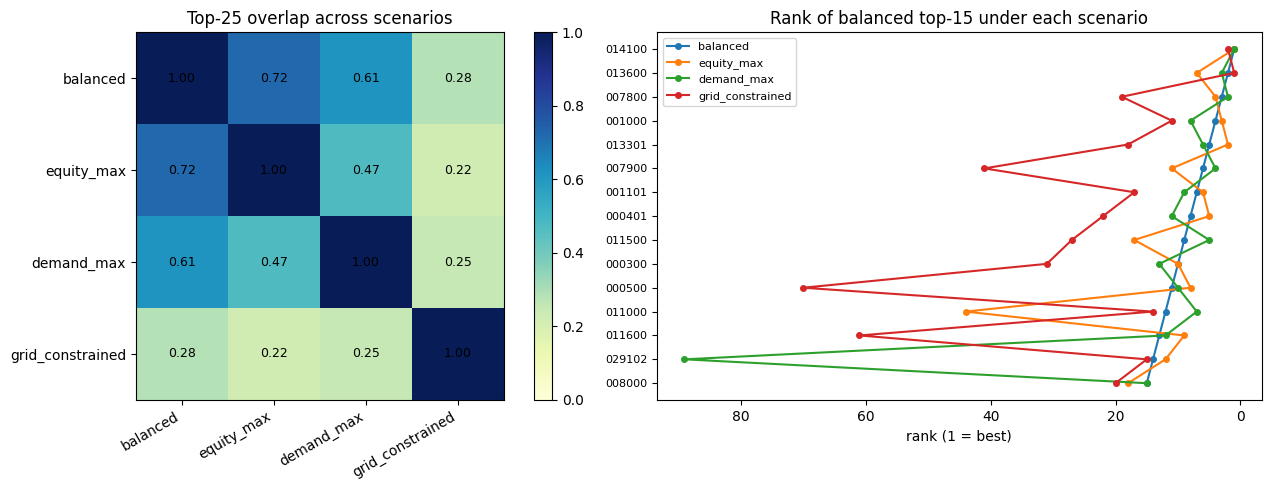

In [32]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(14,5))
im=ax[0].imshow(J.values.astype(float),cmap="YlGnBu",vmin=0,vmax=1)
ax[0].set_xticks(range(len(names))); ax[0].set_xticklabels(names,rotation=30,ha="right")
ax[0].set_yticks(range(len(names))); ax[0].set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)): ax[0].text(j,i,f"{J.values[i,j]:.2f}",ha="center",va="center",fontsize=9)
ax[0].set_title(f"Top-{N} overlap across scenarios"); fig.colorbar(im,ax=ax[0],fraction=.046)
top15=m.sort_values("suitability_score",ascending=False).head(15)["geoid"].tolist()
for name in names:
    ax[1].plot([scen_scores[name].get(g,np.nan) for g in top15],range(len(top15)),"-o",ms=4,label=name)
ax[1].set_yticks(range(len(top15))); ax[1].set_yticklabels([g[-6:] for g in top15],fontsize=8)
ax[1].invert_yaxis(); ax[1].invert_xaxis(); ax[1].set_xlabel("rank (1 = best)")
ax[1].set_title("Rank of balanced top-15 under each scenario"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(CONFIG["output_dir"],"sensitivity.png"),dpi=130,bbox_inches="tight")
plt.show()


## 10. Visualization — suitability map with **address search**

The saved map has a search box (top-right): type any address, it geocodes, drops a pin, and tells you the distance to the nearest recommended site (green line = within your coverage radius, red = outside).

In [33]:
import folium
from folium.plugins import MarkerCluster
from branca.element import MacroElement
from jinja2 import Template
import branca.colormap as cm

score_by_geoid=dict(zip(m["geoid"],m["suitability_score"]))
center=[m["lat"].median(),m["lon"].median()]
# NOTE: folium's "cartodbpositron" shortcut now points at CARTO's basemap CDN,
# which as of their recent policy change returns an "API key required" watermark
# tile for anonymous/keyless use instead of a real basemap. Plain OpenStreetMap
# tile.openstreetmap.org is against OSM's tile usage policy for embedding in an
# app/demo and gets silently blocked (a 403 "Access blocked" tile image, not a
# clean HTTP error). Esri's public ArcGIS Online basemap tiles are free, need no
# API key or signup, and are safe for this kind of embedding.
fmap=folium.Map(location=center,zoom_start=10,tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri &mdash; Esri, DeLorme, NAVTEQ",
    name="Esri Gray Canvas", control=False,
).add_to(fmap)
vmin,vmax=m["suitability_score"].min(),m["suitability_score"].max()
colormap=cm.linear.YlOrRd_09.scale(vmin,vmax); colormap.caption="EV charging suitability"; colormap.add_to(fmap)

def style_fn(feat):
    g=str(feat["properties"].get("geoid","")).zfill(11); v=score_by_geoid.get(g)
    return {"fillColor":colormap(v) if v is not None else "#ccc","color":"#666",
            "weight":0.3,"fillOpacity":0.7 if v is not None else 0.05}
folium.GeoJson(dac_geojson,name="Suitability (tract)",style_function=style_fn,
    tooltip=folium.GeoJsonTooltip(fields=["geoid"],aliases=["Tract:"])).add_to(fmap)

top_layer=folium.FeatureGroup(name=f"Top {N} recommended sites").add_to(fmap)
for _,r in top_overall.iterrows():
    if pd.isna(r["lat"]): continue
    folium.CircleMarker([r["lat"],r["lon"]],radius=6,color="#08306b",fill=True,fill_opacity=0.9,
        popup=folium.Popup(f"<b>Rank #{int(r['rank'])}</b><br>Tract {r['geoid']}<br>{r['county']}<br>"
            f"Score {r['suitability_score']:.1f}<br>DAC {bool(r['is_dac'])}<br>"
            f"EV/1k {r['ev_per_1k']:.1f}<br>Chargers ≤{R}km {int(r['stations_within_r'])}",max_width=260)
        ).add_to(top_layer)

st_layer=folium.FeatureGroup(name="Existing chargers",show=False).add_to(fmap)
mc=MarkerCluster().add_to(st_layer)
for _,s in stations_df.iterrows():
    folium.CircleMarker([s["lat"],s["lon"]],radius=3,color="#2b8cbe",fill=True,fill_opacity=0.6,
        popup=str(s.get("station_name",""))).add_to(mc)

cr_layer=folium.FeatureGroup(name="Charge Ready NY (installed)",show=False).add_to(fmap)
for _,c in charge_ready_df.iterrows():
    folium.CircleMarker([c["lat"],c["lon"]],radius=3,color="#31a354",fill=True,fill_opacity=0.6).add_to(cr_layer)

rec_sites=[{"rank":int(r["rank"]),"lat":float(r["lat"]),"lon":float(r["lon"]),
            "county":str(r["county"]),"dac":bool(r["is_dac"]),"score":float(r["suitability_score"])}
           for _,r in top_overall.iterrows() if pd.notna(r["lat"])]

class AddressSearch(MacroElement):
    def __init__(self, rec_sites, threshold_km):
        super().__init__()
        self.rec_json=json.dumps(rec_sites); self.threshold=threshold_km
        self._template=Template(r'''
{% macro script(this,kwargs) %}
var REC={{this.rec_json}}; var THR={{this.threshold}}; var MAP={{this._parent.get_name()}};
function hv(a,b,c,d){var R=6371,p=Math.PI/180;var x=Math.sin((c-a)*p/2)**2+Math.cos(a*p)*Math.cos(c*p)*Math.sin((d-b)*p/2)**2;return 2*R*Math.asin(Math.sqrt(x));}
var ctl=L.control({position:'topright'});
ctl.onAdd=function(){var d=L.DomUtil.create('div','leaflet-bar');d.style.background='#fff';d.style.padding='6px';d.style.font='12px sans-serif';
d.innerHTML='<input id="aIn" placeholder="Type an address…" style="width:190px"/><button id="aGo">Find</button><div id="aOut" style="max-width:230px;margin-top:4px;color:#333"></div>';
L.DomEvent.disableClickPropagation(d);return d;};
ctl.addTo(MAP);
var mk=null,ln=null;
function esc(s){return String(s==null?'':s).replace(/[&<>"']/g,function(c){return {'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;',"'":'&#39;'}[c];});}
setTimeout(function(){
 document.getElementById('aGo').onclick=function(){
  var q=document.getElementById('aIn').value; if(!q)return;
  document.getElementById('aOut').innerHTML='Searching…';
  fetch('https://nominatim.openstreetmap.org/search?format=json&limit=1&countrycodes=us&q='+encodeURIComponent(q))
  .then(r=>r.json()).then(function(j){
   if(!j||!j.length){document.getElementById('aOut').innerHTML='Address not found';return;}
   var lat=parseFloat(j[0].lat),lon=parseFloat(j[0].lon);
   if(mk)MAP.removeLayer(mk); if(ln)MAP.removeLayer(ln);
   mk=L.marker([lat,lon]).addTo(MAP); MAP.setView([lat,lon],13);
   var best=null,bd=1e9; REC.forEach(function(s){var dd=hv(lat,lon,s.lat,s.lon); if(dd<bd){bd=dd;best=s;}});
   var near=bd<=THR;
   ln=L.polyline([[lat,lon],[best.lat,best.lon]],{color:near?'green':'red',dashArray:'6,6'}).addTo(MAP);
   mk.bindPopup('<b>'+esc(q)+'</b><br>Nearest recommended site: #'+esc(best.rank)+' ('+esc(best.county)+(best.dac?', DAC':'')+')<br>'+bd.toFixed(2)+' km away<br>'+(near?'✓ within '+THR+' km of a recommended site':'✗ not within '+THR+' km')).openPopup();
   document.getElementById('aOut').innerHTML=(near?'✓ ':'✗ ')+bd.toFixed(2)+' km to site #'+esc(best.rank)+' ('+esc(best.county)+')';
  }).catch(function(e){document.getElementById('aOut').innerHTML='Geocoder error';});
 };
},400);
{% endmacro %}''')

fmap.add_child(AddressSearch(rec_sites, CONFIG["coverage_radius_km"]))
folium.LayerControl(collapsed=False).add_to(fmap)
map_path=os.path.join(CONFIG["output_dir"],"ev_site_suitability_map.html")
fmap.save(map_path); print("Saved map ->",map_path,"(open it and use the search box, top-right)")
fmap


Saved map -> outputs\ev_site_suitability_map.html (open it and use the search box, top-right)


### 10.1  Address lookup from the notebook — `locate_address()`

Geocodes a US address (Census geocoder, OSM fallback), reports the tract it falls in, that tract's suitability rank, and the nearest recommended site.

In [34]:
def geocode(address):
    try:
        u="https://geocoding.geo.census.gov/geocoder/locations/onelineaddress"
        j=http_get(u,{"address":address,"benchmark":"Public_AR_Current","format":"json"}).json()
        mt=j.get("result",{}).get("addressMatches",[])
        if mt:
            c=mt[0]["coordinates"]; return (c["y"],c["x"],mt[0].get("matchedAddress",address))
    except Exception: pass
    try:
        j=http_get("https://nominatim.openstreetmap.org/search",
                   {"format":"json","limit":1,"countrycodes":"us","q":address}).json()
        if j: return (float(j[0]["lat"]),float(j[0]["lon"]),j[0].get("display_name",address))
    except Exception: pass
    return (None,None,None)

def locate_address(address, show_map=True):
    lat,lon,label=geocode(address)
    if lat is None:
        print(f"Could not geocode: {address}"); return None
    tract=None
    for f in dac_geojson.get("features",[]):
        if point_in_feature(lat,lon,f):
            tract=str(f["properties"].get("geoid","")).zfill(11); break
    row=m[m["geoid"]==tract].head(1) if tract else pd.DataFrame()
    d=[(haversine_km(lat,lon,r["lat"],r["lon"]),r) for _,r in top_overall.iterrows() if pd.notna(r["lat"])]
    bd,br=min(d,key=lambda x:x[0])
    near=bd<=CONFIG["coverage_radius_km"]
    print(f"📍 {label}\n   ({lat:.5f}, {lon:.5f})")
    if len(row):
        rr=row.iloc[0]
        print(f"   Falls in tract {tract} | {rr['county']} | DAC={bool(rr['is_dac'])} | "
              f"suitability {rr['suitability_score']:.1f} (rank #{int(rr['rank'])} of {len(m)})")
    else:
        print(f"   Tract: {'outside modelled area' if tract is None else tract}")
    print(f"   Nearest recommended site: rank #{int(br['rank'])} in {br['county']} — {bd:.2f} km away")
    print(f"   {'✓ WITHIN' if near else '✗ NOT within'} the {CONFIG['coverage_radius_km']} km coverage radius of a recommended site")
    if not show_map: return {"lat":lat,"lon":lon,"tract":tract,"nearest_rank":int(br['rank']),"nearest_km":bd,"served":near}
    fm=folium.Map(location=[lat,lon],zoom_start=13,tiles="cartodbpositron")
    folium.Marker([lat,lon],popup=label,icon=folium.Icon(color="blue")).add_to(fm)
    folium.Circle([lat,lon],radius=CONFIG["coverage_radius_km"]*1000,color="#3186cc",fill=True,fill_opacity=0.08).add_to(fm)
    for _,r in top_overall.head(10).iterrows():
        if pd.isna(r["lat"]): continue
        folium.CircleMarker([r["lat"],r["lon"]],radius=6,color="#08306b",fill=True,fill_opacity=0.9,
            popup=f"Rank #{int(r['rank'])} ({r['county']})").add_to(fm)
    folium.PolyLine([[lat,lon],[br['lat'],br['lon']]],color="green" if near else "red",dash_array="6,6").add_to(fm)
    return fm

try:
    demo=locate_address("Grand Concourse, Bronx, NY")
except Exception as e:
    print("geocoder unreachable in this environment — call locate_address('<addr>') when online:",type(e).__name__)
    demo=None
demo


📍 Grand Concourse, Fordham, The Bronx, Bronx County, New York, 10468, United States
   (40.85830, -73.89923)
   Falls in tract 36005038301 | Bronx | DAC=True | suitability 44.8 (rank #432 of 2325)
   Nearest recommended site: rank #21 in Westchester — 7.92 km away
   ✗ NOT within the 2.0 km coverage radius of a recommended site


## 11. Validation — do the recommendations hold up?

Four independent checks (your July *"validate recommended locations against operational, technical, and environmental considerations"* task):

1. **Redundancy vs existing chargers** — a good recommendation shouldn't already be saturated with NREL chargers.
2. **Corroboration vs Charge Ready NY** — sites near where NY *already funded* charging are directionally validated; sites far from any award are genuinely new opportunities.
3. **DAC coverage** — share of DAC population whose tract centroid is within the coverage radius of a recommended site (equity delivery).
4. **Grid feasibility** — (live grid only) flag any recommended site whose feeder EV headroom is in the bottom quartile.

In [35]:
cr_lat=charge_ready_df["lat"].to_numpy(); cr_lon=charge_ready_df["lon"].to_numpy()
def nearest_km(lat,lon,arr_lat,arr_lon):
    if pd.isna(lat) or not len(arr_lat): return np.nan
    return float(min(haversine_km(lat,lon,a,b) for a,b in zip(arr_lat,arr_lon)))

val=top_overall.copy()
val["nearest_charge_ready_km"]=[nearest_km(la,lo,cr_lat,cr_lon) for la,lo in zip(val["lat"],val["lon"])]
val["corroborated"]=val["nearest_charge_ready_km"]<=CONFIG["coverage_radius_km"]
val["already_has_charger"]=val["stations_within_r"]>0
cov_r=CONFIG["coverage_radius_km"]

print(f"1) Redundancy: {val['already_has_charger'].mean():.0%} of top {N} already have a charger ≤{R}km "
      f"(lower is better)")
print(f"2) Corroboration: {val['corroborated'].mean():.0%} of top {N} are within {cov_r}km of a Charge Ready NY install; "
      f"{(~val['corroborated']).mean():.0%} are NEW opportunities")

site_lat=top_overall["lat"].to_numpy(); site_lon=top_overall["lon"].to_numpy()
dac_tracts=m[m["is_dac"]].copy()
dac_tracts["served"]=[nearest_km(la,lo,site_lat,site_lon)<=cov_r for la,lo in zip(dac_tracts["lat"],dac_tracts["lon"])]
served_pop=dac_tracts.loc[dac_tracts["served"],"population_count"].sum()
total_dac_pop=dac_tracts["population_count"].sum()
print(f"3) DAC coverage: {served_pop/total_dac_pop:.0%} of DAC population within {cov_r}km of a top-{N} site "
      f"({int(served_pop):,}/{int(total_dac_pop):,})")

if GRID_MODE=="live" and val["grid_headroom_mw"].notna().any():
    q1=m["grid_headroom_mw"].quantile(0.25)
    val["low_grid_headroom"]=val["grid_headroom_mw"]<q1
    print(f"4) Grid: {val['low_grid_headroom'].mean():.0%} of top {N} on bottom-quartile feeder headroom "
          f"(<{q1:.2f} MW) — review for make-ready cost")
else:
    print("4) Grid: proxy mode — set Con Ed hosting-capacity URL to enable feeder feasibility flags")

display(val[["rank","geoid","county","is_dac","suitability_score","stations_within_r",
             "nearest_charge_ready_km","corroborated","already_has_charger"]].round(2))


1) Redundancy: 60% of top 25 already have a charger ≤2.0km (lower is better)
2) Corroboration: 68% of top 25 are within 2.0km of a Charge Ready NY install; 32% are NEW opportunities
3) DAC coverage: 6% of DAC population within 2.0km of a top-25 site (295,331/4,551,630)
4) Grid: 0% of top 25 on bottom-quartile feeder headroom (<0.00 MW) — review for make-ready cost


,rank,geoid,county,is_dac,suitability_score,stations_within_r,nearest_charge_ready_km,corroborated,already_has_charger
0,1,36119014100,Westchester,True,74.82,0,0.29,True,False
1,2,36119013600,Westchester,True,70.75,0,2.40,False,False
2,3,36119007800,Westchester,True,70.61,0,0.56,True,False
3,4,36119001000,Westchester,True,69.31,1,0.84,True,True
4,5,36119013301,Westchester,True,68.45,0,3.14,False,False
5,6,36119007900,Westchester,True,67.78,0,0.73,True,False
6,7,36119001101,Westchester,True,67.77,2,0.58,True,True
7,8,36119000401,Westchester,True,66.58,1,0.21,True,True
8,9,36119011500,Westchester,True,66.54,0,0.76,True,False
9,10,36119000300,Westchester,True,66.01,2,0.45,True,True


## 12. Export deliverables

In [36]:
master_out=os.path.join(CONFIG["output_dir"],"master_integrated_dataset")
if HAVE_PARQUET: m.to_parquet(master_out+".parquet",index=False)
m.to_csv(master_out+".csv",index=False)
top_overall.to_csv(os.path.join(CONFIG["output_dir"],"ranked_site_recommendations.csv"),index=False)
top_dac.to_csv(os.path.join(CONFIG["output_dir"],"ranked_site_recommendations_DAC.csv"),index=False)
val.to_csv(os.path.join(CONFIG["output_dir"],"validation_report.csv"),index=False)

manifest={"generated_at":time.strftime("%Y-%m-%d %H:%M:%S"),
    "counties":CONFIG["target_counties"],"n_tracts_scored":int(len(m)),
    "weights":CONFIG["weights"],"grid_mode":GRID_MODE,"grid_label":GRID_LABEL,
    "coverage_radius_km":CONFIG["coverage_radius_km"],
    "sources":{"dac":"SYNTHETIC" if SYNTH_DAC else "LIVE 2e6c-s6fp",
        "ev_registrations":"SYNTHETIC" if SYNTH_EV else "LIVE 3vp6-cxmr",
        "stations":"SYNTHETIC" if SYNTH_ST else "LIVE NREL AFDC",
        "grid":GRID_MODE.upper(),
        "charge_ready":"SYNTHETIC" if SYNTH_CR else "LIVE 9wxk-hakb"},
    "outputs":(["master_integrated_dataset.parquet"] if HAVE_PARQUET else [])+[
        "master_integrated_dataset.csv","ranked_site_recommendations.csv",
        "ranked_site_recommendations_DAC.csv","validation_report.csv",
        "ev_site_suitability_map.html","sensitivity.png"]}
with open(os.path.join(CONFIG["output_dir"],"run_manifest.json"),"w") as f: json.dump(manifest,f,indent=2)
print("Deliverables in ./outputs :")
for o in manifest["outputs"]: print("  -",o)
print("\nProvenance:",manifest["sources"])


Deliverables in ./outputs :
  - master_integrated_dataset.parquet
  - master_integrated_dataset.csv
  - ranked_site_recommendations.csv
  - ranked_site_recommendations_DAC.csv
  - validation_report.csv
  - ev_site_suitability_map.html
  - sensitivity.png

Provenance: {'dac': 'LIVE 2e6c-s6fp', 'ev_registrations': 'LIVE 3vp6-cxmr', 'stations': 'SYNTHETIC', 'grid': 'LIVE', 'charge_ready': 'LIVE 9wxk-hakb'}


## 13. Status & orchestration

**Delivered this quarter:** real Con Ed grid capacity (with proxy fallback), density-based accessibility, sensitivity analysis, Charge Ready NY validation, and address search — all on one cleaned, integrated dataset with ranked outputs.

**Airflow (Q1 ETL sprint):** the ingest + score steps are shipped as `ev_pipeline.py` and wired into `dags/ev_site_selection_dag.py` (extract DAC / EV / stations / grid / charge-ready → clean+integrate → score → export). Drop the `dags/` file into your Airflow `dags_folder`, put `ev_pipeline.py` on the `PYTHONPATH`, and the same functions run as scheduled tasks.

**To go fully live:** (1) keep your NREL key in an env var; (2) paste the Con Ed hosting-capacity layer URL into `CONFIG["coned_hosting_capacity_url"]`; (3) delete `data/cache/` to force a refresh; (4) Run All. Watch the `LIVE`/`SYNTHETIC` banners and `run_manifest.json` to confirm provenance.


**This quarter's build-out:** a Django + DRF backend and a Folium-based live dashboard now sit on top of the same pipeline — see Section 14 below.

## 14. End-to-end web app — Django backend + live-synced Folium dashboard

Everything above (ETL, scoring, ranked recommendations) also runs behind a real web
application in [`webapp/`](webapp/):

- **Backend** — Django + Django REST Framework, SQLite. A `sync_sites` management
  command reads `outputs/ranked_site_recommendations.csv`, `master_integrated_dataset.csv`
  and `run_manifest.json` — the exact files Section 12 just wrote — into the database.
  Pass `--full` and it re-runs `ev_pipeline.run_all()` first. That's the "connect site
  selection results directly to the ETL pipeline for live updates" piece: one source of
  truth (`ev_pipeline.py`), two consumers (this notebook and the web app).
- **API** — `GET /api/sites/` (filter by `county`, `is_dac`, `min_score`; order by
  rank/score), `GET /api/stats/` (county breakdown, DAC coverage, provenance),
  `POST /api/sync/` (re-sync now, optionally `?full=1`), `GET /api/geocode/` and
  `GET /api/nearest/` (server-side autocomplete + nearest-site lookup).
- **Frontend** — a dashboard (animated stat cards, county chart, live "Sync now" button)
  embedding a real **Folium** map: type an address for live autocomplete suggestions
  (proxied through `/api/geocode/` → Photon, no API key needed), pick one, and it drops a
  pin with a line to the nearest recommended site — green if within the coverage radius,
  red if not.

Run the next few cells to start it and see it live, right here in the notebook.

In [ ]:
import subprocess, sys, time, os
from pathlib import Path
import requests

WEBAPP_DIR = Path("webapp").resolve()
WEBAPP_PORT = int(os.environ.get("WEBAPP_DEMO_PORT", 8877))
WEBAPP_URL = f"http://127.0.0.1:{WEBAPP_PORT}"

try:
    import django, rest_framework  # noqa: F401
    HAVE_DJANGO = True
except ImportError:
    HAVE_DJANGO = False
    print("Django/DRF not installed — run:  pip install django djangorestframework")

HAVE_WEBAPP = HAVE_DJANGO and (WEBAPP_DIR / "manage.py").exists()
if HAVE_DJANGO and not HAVE_WEBAPP:
    print(f"No Django project found at {WEBAPP_DIR} — skipping the live demo.")

### 14.1  Migrate + sync the database from this run's ETL outputs

In [ ]:
def run_manage(*args, check=True):
    r = subprocess.run([sys.executable, "manage.py", *args], cwd=WEBAPP_DIR,
                        capture_output=True, text=True)
    print((r.stdout or r.stderr).strip())
    if check and r.returncode != 0:
        raise RuntimeError(f"manage.py {' '.join(args)} failed:\n{r.stderr}")
    return r

if HAVE_WEBAPP:
    run_manage("migrate", "--noinput")
    run_manage("sync_sites")  # add "--full" to re-run ev_pipeline.run_all() first instead

### 14.2  Start the Django dev server (background process)

In [ ]:
django_proc = None
if HAVE_WEBAPP:
    django_proc = subprocess.Popen(
        [sys.executable, "manage.py", "runserver", f"127.0.0.1:{WEBAPP_PORT}", "--noreload"],
        cwd=WEBAPP_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    for _ in range(40):
        try:
            if requests.get(f"{WEBAPP_URL}/api/stats/", timeout=1).ok:
                print(f"Django dev server up -> {WEBAPP_URL}")
                break
        except requests.exceptions.RequestException:
            time.sleep(0.5)
    else:
        print("Server didn't come up in time — inspect django_proc.stdout for errors")

### 14.3  Exercise the API

In [ ]:
if HAVE_WEBAPP:
    stats = requests.get(f"{WEBAPP_URL}/api/stats/").json()
    print("GET /api/stats/ ->")
    print(json.dumps(stats, indent=2))

    top5 = requests.get(f"{WEBAPP_URL}/api/sites/", params={"ordering": "rank", "limit": 5}).json()
    print("\nGET /api/sites/?ordering=rank&limit=5 ->")
    for s in top5["results"]:
        print(f"  #{s['rank']:>2} {s['county']:<12} score={s['suitability_score']:.1f}  DAC={s['is_dac']}")

    sugg = requests.get(f"{WEBAPP_URL}/api/geocode/", params={"q": "Grand Concourse, Bronx"}).json()
    print("\nGET /api/geocode/?q=Grand Concourse, Bronx ->")
    for r_ in sugg["results"][:3]:
        print("  •", r_["label"])

    if sugg["results"]:
        p = sugg["results"][0]
        near = requests.get(f"{WEBAPP_URL}/api/nearest/",
                             params={"lat": p["lat"], "lon": p["lon"], "radius_km": 2}).json()
        print(f"\nNearest recommended site to '{p['label']}':"
              f" #{near['rank']} ({near['county']}), {near['distance_km']} km away,"
              f" within coverage: {near['within_coverage']}")

### 14.4  Live dashboard

Stat cards, county breakdown chart, the Folium suitability map with address
autocomplete, and the ranked-sites table — all reading live from the API above.
Click **Sync now** to re-load straight from `outputs/` without leaving the page.

In [ ]:
from IPython.display import IFrame

IFrame(src=WEBAPP_URL, width="100%", height=900) if HAVE_WEBAPP else \
    print("Web app not running — see Section 14 setup cells above.")

**Also available while the server is running:** the Django admin at
[`/admin/`](http://127.0.0.1:8877/admin/) (run `python manage.py createsuperuser`
in `webapp/` first) and the browsable API at [`/api/sites/`](http://127.0.0.1:8877/api/sites/).

Run the cell below when you're done to stop the dev server.

In [ ]:
if django_proc is not None:
    django_proc.terminate()
    django_proc.wait(timeout=5)
    print("Django dev server stopped.")